In [16]:
import laspy
#import numpy as np


with laspy.open(r"C:\Users\jakad\Downloads\GK_466_126.laz") as liz: 
    liz.header.point_count
    liz.header.x_min
    liz.header.x_max
    liz.header.y_min
    liz.header.y_max
    liz.header.z_min
    liz.header.z_max
    liz.header.vlrs[0]
    liz.header.version

print(liz.header.point_count, ',', liz.header.x_min, '-', liz.header.x_max, ',', liz.header.y_min, '-', liz.header.y_max, ',', liz.header.z_min, '-', liz.header.z_max, ',', liz.header.version)




25808191 , 466000.0 - 467000.0 , 126000.0 - 127000.0 , 610.84 - 1199.84 , 1.2


In [17]:
import laspy 
import numpy as np

#create a dummy data
my_data_xx, my_data_yy = np.meshgrid(np.linspace(-20, 20, 15), np.linspace(-20, 20, 15))
my_data_zz = my_data_xx ** 2 + 0.25 * my_data_yy ** 2
my_data = np.hstack((my_data_xx.reshape((-1, 1)), my_data_yy.reshape((-1, 1)), my_data_zz.reshape((-1, 1))))

#las header
header = laspy.LasHeader(point_format=3, version='1.2')
header.offset = np.min(my_data, axis=0)
header.scales = np.array([0.1, 0.1, 0.1])

#las.writer 

with laspy.open(r"C:\Users\jakad\Downloads\GK_466_126.laz", mode='w', header=header) as wrt:
    point_record = laspy.ScaleAwarePointRecord.zeros(my_data.shape[0], header=header)
    point_record.x = my_data[:, 0]
    point_record.y = my_data[:, 1]
    point_record.z = my_data[:, 2]

    wrt.write_points(point_record)


In [ ]:
import laspy 
import numpy as np 

las = laspy.read(r"C:\Users\jakad\Downloads\GK_466_126.laz")

#Finding a bad error! If it have of course!
X_invalid = (las.header.min[0] > las.x) | (las.header.max[0] < las.x)
Y_invalid = (las.header.min[1] > las.y) | (las.header.max[1] < las.y)
Z_invalid = (las.header.min[2] > las.z) | (las.header.max[2] < las.z)
bad_indices = np.where(X_invalid, Y_invalid, Z_invalid)

print(bad_indices)


#coord = np.vstack(las.x, las.y, las.z).transpose()
#But then I need changd that into a little bit diffrent algorithm, with same result ... I hope so!
coords = np.column_stack((
    np.asarray(las.x),
    np.asarray(las.y),
    np.asarray(las.z),
))
first_point = coords[0,:]
distances = np.sqrt(np.sum((coords - first_point) ** 2, axis=1))
mask = distances < 500
points_kept = las.points[mask]
print("We kept %i points out of %i total" % (len(points_kept), len(las.points)))

[False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False False False False False Fa

In [1]:
import laspy
#import numpy as np 

las = laspy.read(r"C:\Users\jakad\Downloads\GK_466_126.laz")

ground_points = las.points[las.number_of_returns == las.return_number]

print(f"{len(ground_points)} points out of {len(las.points)} were ground points.")


225 points out of 225 were ground points.


Intensity:  [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0]
Min: 0, Max: 0, 0.0
<ScaleAwarePointRecord(fmt: <PointFormat(3, 0 bytes of extra dims)>, len: 0, point size: 34)>


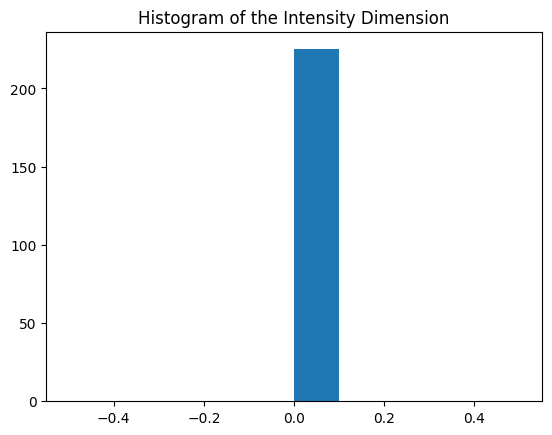

In [10]:
import laspy
import matplotlib.pyplot as plt

las = laspy.read(r"C:\Users\jakad\Downloads\GK_466_126.laz")
intensity = las.intensity

print('Intensity: ', intensity)
print(f'Min: {intensity.min()}, Max: {intensity.max()}, {intensity.max()-intensity.min() / 2}')

#points per intensity
high_int = las.points[las.intensity > 1000]
print(high_int)
plt.hist(intensity)
plt.title('Histogram of the Intensity Dimension')
plt.show()

21643424
{'Ground [2]': 9361488, 'Low_vegetation [3]': 1034538, 'Medium_vegetation [4]': 2959584, 'High_vegetation [5]': 7896943, 'Building [6]': 334106, 'Low Noise [7]': 473}


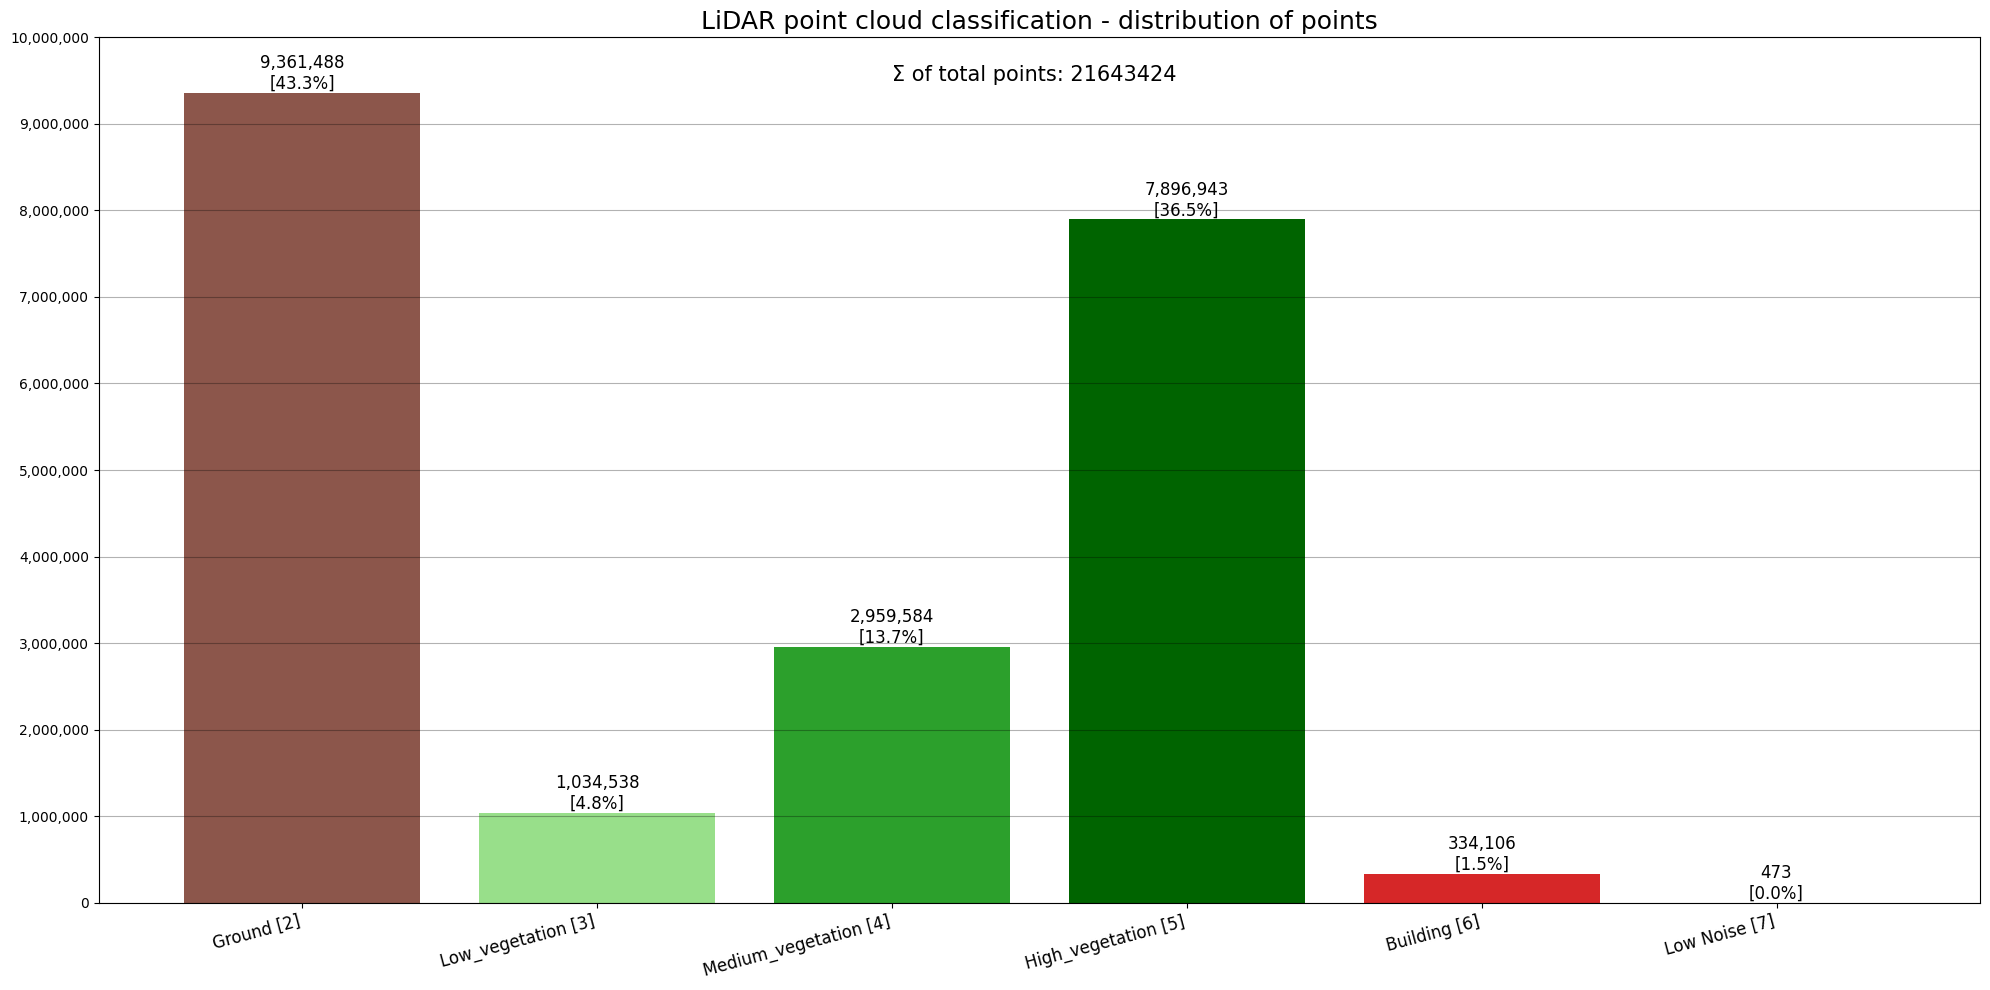

In [84]:
import laspy
import matplotlib.pyplot as plt 
import numpy as np
from matplotlib import ticker

las = laspy.read(r"C:\Users\jakad\Downloads\GKOT_464_88.laz")

print(len(las.points))

classification = np.array(las.classification)


classified = {
    #'All_points [SUM]': (las.points),
    'Ground [2]': int(np.sum(classification == 2)),
    'Low_vegetation [3]': int(np.sum(classification == 3)),
    'Medium_vegetation [4]': int(np.sum(classification == 4)),
    'High_vegetation [5]': int(np.sum(classification == 5)),
    'Building [6]': int(np.sum(classification == 6)),
    'Low Noise [7]': int(np.sum(classification == 7)),
}

print(classified)

names = list(classified.keys())
all_points = list(classified.values())

plt.figure(figsize=(20, 10))

bars = plt.bar(names, all_points, color=["#8c564b", "#98df8a", "#2ca02c", "#006400", "#d62728", "#7f7f7f"])
for bar, value in zip(bars, all_points):
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            value,
            f'{value:,}\n[{value / len(las.points):.01%}]',
            ha='center',
            va='bottom',
            fontsize=12
        )

plt.title('LiDAR point cloud classification - distribution of points', fontsize=18)
plt.text(2, 9500000, f'Σ of total points: {len(las.points)}', fontsize=15)
plt.xticks(rotation=15, ha='right', fontsize=12)
plt.grid(axis='y', alpha=0.3, color='black')
#plt.grid(axis='x', alpha=0.3)
formatter = ticker.ScalarFormatter()
formatter.set_scientific(False)
ax = plt.gca()

upper = np.ceil(max(all_points) / 1_000_000) * 1_000_000
ax.set_yticks(np.arange(0, upper + 1, 1_000_000))
ax.yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))

plt.tight_layout()
plt.show()